In [13]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import sklearn 
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier

In [14]:
df = pd.read_csv(r"D:\FinTech\MasterClass-FinTech-01\session_3\barobach.csv")
display(df.columns)
df.head

Index(['name', 'age', 'gender', 'education_level', 'education_status', 'major',
       'city', 'marital_status', 'numpy', 'pandas', 'matplotlib',
       'machine_learning', 'deep_learning', 'sql', 'target'],
      dtype='str')

<bound method NDFrame.head of                         name  age  gender education_level education_status  \
0                      آرمین   22    male        bachelor      in_progress   
1               آریان عمرانی   23    male        bachelor        completed   
2     امیرحسین رضازاده حنایی   26    male          master      in_progress   
3                    امیررضا   22    male        bachelor      in_progress   
4                      ساجده   26  female          master        completed   
5                       سروش   25    male        bachelor        completed   
6             سید آرین هاشمی   24    male        bachelor      in_progress   
7                  سید عرفان   26    male             phd      in_progress   
8          سیده عادله مصطفوی   21  female        bachelor      in_progress   
9                 علی شهروزی   23    male          master      in_progress   
10                    علیرضا   24    male        bachelor        completed   
11               فائزه آزادی   32 

In [15]:

import pandas as pd
import numpy as np

# Assume your original dataset is stored in df
df2 = df.copy()

# 1. Drop name
df = df.drop(columns=["name"])

# 2. Age: do nothing

# 3. Gender: male, female, unknown
df["gender"] = (
    df["gender"]
    .replace(r"^\s*$", np.nan, regex=True)
    .str.strip()
    .str.lower()
    .map({
        "male": 0,
        "female": 1
    })
    .fillna(2)
    .astype(int)
)

# 4. Education level: bachelor, master, phd, unknown
df["education_level"] = (
    df["education_level"]
    .replace(r"^\s*$", np.nan, regex=True)
    .str.strip()
    .str.lower()
    .map({
        "bachelor": 0,
        "master": 1,
        "phd": 2
    })
    .fillna(3)
    .astype(int)
)

# 5. Education status: in_progress, completed
df["education_status"] = (
    df["education_status"]
    .replace(r"^\s*$", np.nan, regex=True)
    .str.strip()
    .str.lower()
    .map({
        "in_progress": 0,
        "completed": 1
    })
    .astype("Int64")
)

# 6. Major: automatically encode distinct categories
df["major"] = (
    df["major"]
    .replace(r"^\s*$", np.nan, regex=True)
    .str.strip()
)

df["major"], major_categories = pd.factorize(
    df["major"],
    sort=True
)

# Represent missing major values as -1
df["major"] = df["major"].astype(int)

# 7. City: automatically encode distinct categories
df["city"] = (
    df["city"]
    .replace(r"^\s*$", np.nan, regex=True)
    .str.strip()
)

df["city"], city_categories = pd.factorize(
    df["city"],
    sort=True
)

df["city"] = df["city"].astype(int)

# 8. Marital status: single, married, unknown
df["marital_status"] = (
    df["marital_status"]
    .replace(r"^\s*$", np.nan, regex=True)
    .str.replace("\u00a0", "", regex=False)
    .str.strip()
    .str.lower()
    .map({
        "single": 0,
        "married": 1
    })
    .fillna(2)
    .astype(int)
)

# 9. Skill columns and target: do nothing

print(df)
print("\nMajor mapping:")
print(dict(enumerate(major_categories)))

print("\nCity mapping:")
print(dict(enumerate(city_categories)))


    age  gender  education_level  education_status  major  city  \
0    22       0                0                 0      6     0   
1    23       0                0                 1      1     0   
2    26       0                1                 0      2     0   
3    22       0                0                 0      1     0   
4    26       1                1                 1      6     1   
5    25       0                0                 1      4     0   
6    24       0                0                 0      5     1   
7    26       0                2                 0      0     0   
8    21       1                0                 0      5     0   
9    23       0                1                 0      1     0   
10   24       0                0                 1      7     0   
11   32       1                1                 1      1     0   
12   20       1                3                 0      3     0   
13   23       1                0                 1      2     

In [19]:
import pandas as pd
import numpy as np

categorical_cols = [
    "gender",
    "education_level",
    "education_status",
    "marital_status",
    "major",
    "city"
]

# Normalize missing and blank values
for col in categorical_cols:
    df[col] = df[col].replace(r"^\s*$", np.nan, regex=True)
    df[col] = df[col].astype("string").str.strip()

    # Make missing values an explicit category
    df[col] = df[col].fillna("Unknown")

    # Automatically encode categories as integers
    df[col] = df[col].astype("category").cat.codes

# Drop name
# df = df.drop(columns=["name"])

df

,age,gender,education_level,education_status,major,city,marital_status,numpy,pandas,matplotlib,machine_learning,deep_learning,sql,target
0,22,0,0,0,6,0,2,1,1,1,1,1,1,0
1,23,0,0,1,1,0,2,0,0,0,0,0,1,1
2,26,0,1,0,2,0,2,1,1,1,1,1,1,1
3,22,0,0,0,1,0,2,1,1,1,1,1,1,0
4,26,1,1,1,6,1,0,1,1,1,1,1,1,0
5,25,0,0,1,4,0,0,1,1,1,1,1,1,0
6,24,0,0,0,5,1,0,1,1,1,1,0,0,1
7,26,0,2,0,0,0,1,1,1,1,1,1,0,0
8,21,1,0,0,5,0,2,1,1,1,1,1,1,1
9,23,0,1,0,1,0,2,1,1,1,1,0,1,1


In [20]:
skill_cols = [
    "numpy",
    "pandas",
    "matplotlib",
    "machine_learning",
    "deep_learning",
    "sql"
]

df["skill_score"] = df[skill_cols].sum(axis=1)

print(df[["skill_score"]])

    skill_score
0             6
1             1
2             6
3             6
4             6
5             6
6             4
7             5
8             6
9             5
10            5
11            6
12            5
13            6
14            6
15            2
16            5
17            4
18            6
19            0


In [23]:
df.columns

Index(['age', 'gender', 'education_level', 'education_status', 'major', 'city',
       'marital_status', 'numpy', 'pandas', 'matplotlib', 'machine_learning',
       'deep_learning', 'sql', 'target', 'skill_score'],
      dtype='str')

[Text(0.6, 0.9, 'major <= 5.5\ngini = 0.48\nsamples = 20\nvalue = [8, 12]'),
 Text(0.5, 0.7, 'education_status <= 0.5\ngini = 0.415\nsamples = 17\nvalue = [5, 12]'),
 Text(0.55, 0.8, 'True  '),
 Text(0.2, 0.5, 'major <= 0.5\ngini = 0.278\nsamples = 12\nvalue = [2, 10]'),
 Text(0.1, 0.3, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.3, 0.3, 'major <= 1.5\ngini = 0.165\nsamples = 11\nvalue = [1, 10]'),
 Text(0.2, 0.1, 'gini = 0.32\nsamples = 5\nvalue = [1, 4]'),
 Text(0.4, 0.1, 'gini = 0.0\nsamples = 6\nvalue = [0, 6]'),
 Text(0.8, 0.5, 'major <= 1.5\ngini = 0.48\nsamples = 5\nvalue = [3, 2]'),
 Text(0.7, 0.3, 'marital_status <= 1.0\ngini = 0.444\nsamples = 3\nvalue = [1, 2]'),
 Text(0.6, 0.1, 'gini = 0.5\nsamples = 2\nvalue = [1, 1]'),
 Text(0.8, 0.1, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.9, 0.3, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.7, 0.7, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.6499999999999999, 0.8, '  False')]

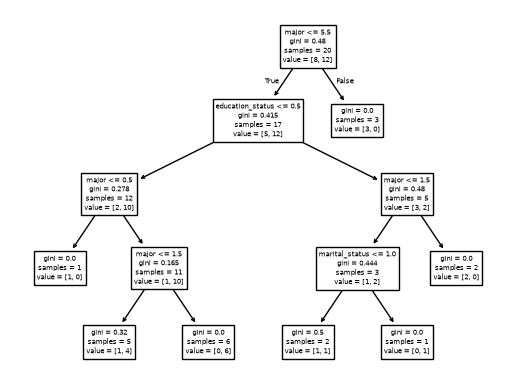

In [29]:
features = ['age', 'gender', 'education_level', 'education_status', 'major', 'city',
       'marital_status', 'skill_score']
X = df[features]
y = df["target"]
dtree = tree.DecisionTreeClassifier(max_depth=4, random_state=42)
dtree = dtree.fit(X,y)
tree.plot_tree(dtree, feature_names=features)

In [30]:
dtree.predict([[23,0,1,1,1,0,1,3]])

c:\Users\OK\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])